# 1 · The experiment: what the right answer looks like

**Project goal:** learn to estimate a program's effect when people *weren't* randomly assigned to it, which is the normal situation in HR. We practice on one of the most famous datasets in causal inference for one reason: **we know the right answer**, so we can grade every method.

**What you'll learn in this notebook**
- Potential outcomes: the language every causal question is written in
- ATE vs. ATT, and which one leaders are usually asking about
- Why randomization makes a simple difference in means correct
- How to get the benchmark estimate and its uncertainty, by hand and with regression

---

### The story

In the mid-1970s, the **National Supported Work Demonstration (NSW)** offered subsidized work experience to people with very weak job histories. Applicants were **randomly assigned**: some got the program, some didn't. The outcome we care about is earnings in 1978 (`re78`).

In 1986, Robert LaLonde asked a question that shaped the field: *if we didn't have the experiment, could the standard statistical methods of the day recover the experimental answer?* He kept the people who got the program, threw away the randomized control group, and swapped in people from national surveys instead. Most methods missed badly. Dehejia and Wahba (1999, 2002) later showed that propensity score methods could get much closer, and later researchers showed how sensitive those results are to choices the analyst makes. You'll reproduce that whole arc in four notebooks.

### The HR translation (keep this in your head the whole time)

| NSW | Your world |
|---|---|
| The work program | A mentoring program, a training, a pay raise, a new manager |
| `re78` (earnings after) | Retention, performance, promotion |
| `re74`, `re75` (earnings before) | Prior performance ratings, prior pay, tenure |
| Survey people swapped in as controls | "Everyone else in the HRIS" |

## 1. Potential outcomes

For each person $i$, imagine two numbers:

- $Y_i(1)$: their 1978 earnings **if they get the program**
- $Y_i(0)$: their 1978 earnings **if they don't**

The effect of the program on person $i$ is

$$\tau_i = Y_i(1) - Y_i(0)$$

The catch: we only ever see **one** of the two. If $T_i = 1$ means "got the program,"

$$Y_i^{\text{observed}} = T_i\,Y_i(1) + (1 - T_i)\,Y_i(0)$$

This is the *fundamental problem of causal inference*. Every method we'll use is a way of filling in the missing half.

Since we can't get $\tau_i$ for one person, we estimate averages:

$$\text{ATE} = E[\,Y(1) - Y(0)\,] \qquad \text{ATT} = E[\,Y(1) - Y(0) \mid T = 1\,]$$

- **ATE** (average treatment effect): the effect if *everyone* got the program. This answers "should we roll it out to the whole company?"
- **ATT** (average treatment effect *on the treated*): the effect for the people who actually got it. This answers "did it work for the people who went through it?"

Most program evaluations estimate the ATT, and so will we.

## 2. Why randomization works

Random assignment means $T$ is independent of the potential outcomes: $\big(Y(0), Y(1)\big) \perp T$. A coin flip doesn't know who would have earned more.

That gives us the one fact that makes everything easy:

$$E[\,Y(0) \mid T = 1\,] = E[\,Y(0) \mid T = 0\,]$$

In words: the control group's average outcome is a fair stand-in for what the treated group *would have* earned without the program. So

$$\underbrace{E[Y \mid T=1] - E[Y \mid T=0]}_{\text{difference in means (what we can compute)}} = E[Y(1) \mid T=1] - E[Y(0) \mid T=1] = \text{ATT}$$

Hold onto that middle step. In notebook 2 it breaks, and the size of the break has a name.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

from utils import loadData

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
experiment, cps = loadData()
experiment.head()

,treat,age,educ,black,hisp,marr,nodegree,re74,re75,re78
0,1,37,11,1,0,1,1,0.00,0.00,"9,930.05"
1,1,22,9,0,1,0,1,0.00,0.00,"3,595.89"
2,1,30,12,1,0,0,0,0.00,0.00,"24,909.45"
3,1,27,11,1,0,0,1,0.00,0.00,"7,506.15"
4,1,33,8,1,0,0,1,0.00,0.00,289.79


**The columns**

| column | meaning |
|---|---|
| `treat` | 1 = randomly assigned to the program, 0 = randomly assigned to control |
| `age`, `educ` | age in years, years of schooling |
| `black`, `hisp` | race/ethnicity indicators |
| `marr` | 1 = married |
| `nodegree` | 1 = no high school degree |
| `re74`, `re75` | earnings in 1974 and 1975 (before the program) |
| `re78` | earnings in 1978 (after the program): **the outcome** |

This is the Dehejia-Wahba subsample of the experiment: 185 treated, 260 controls.

> **Predict first.** In a randomized experiment, how different should the two groups look on age, education, and 1975 earnings? Write down your guess, then run the next cell.

In [2]:
groupMeans = experiment.groupby("treat").mean().T
groupMeans.columns = ["control", "treated"]
groupMeans["difference"] = groupMeans["treated"] - groupMeans["control"]
groupMeans

,control,treated,difference
age,25.05,25.82,0.76
educ,10.09,10.35,0.26
black,0.83,0.84,0.02
hisp,0.11,0.06,-0.05
marr,0.15,0.19,0.04
nodegree,0.83,0.71,-0.13
re74,"2,107.03","2,095.57",-11.45
re75,"1,266.91","1,532.06",265.15
re78,"4,554.80","6,349.14","1,794.34"


The groups look alike on the things measured *before* the program. They aren't identical; chance always leaves small gaps (look at `nodegree` and `hisp`). The big gap is in `re78`, which is measured *after*. That's the program.

## 3. The benchmark estimate, by hand

The estimate is just the difference in means:

$$\hat\tau = \bar Y_1 - \bar Y_0$$

Its standard error (Welch's version, which doesn't assume equal variances):

$$SE(\hat\tau) = \sqrt{\frac{s_1^2}{n_1} + \frac{s_0^2}{n_0}}$$

and an approximate 95% confidence interval is $\hat\tau \pm 1.96 \times SE$.

In [3]:
treated = experiment.loc[experiment.treat == 1, "re78"]
control = experiment.loc[experiment.treat == 0, "re78"]

diffInMeans = treated.mean() - control.mean()
se = np.sqrt(treated.var(ddof=1) / len(treated) + control.var(ddof=1) / len(control))
ciLow, ciHigh = diffInMeans - 1.96 * se, diffInMeans + 1.96 * se
tStat = diffInMeans / se

print(f"treated mean: ${treated.mean():,.0f}   control mean: ${control.mean():,.0f}")
print(f"difference:   ${diffInMeans:,.0f}   (se ${se:,.0f})")
print(f"95% ci:       ${ciLow:,.0f} to ${ciHigh:,.0f}   t = {tStat:.2f}")
print(stats.ttest_ind(treated, control, equal_var=False))  # same thing, scipy's version

treated mean: $6,349   control mean: $4,555
difference:   $1,794   (se $671)
95% ci:       $479 to $3,109   t = 2.67
TtestResult(statistic=np.float64(2.674145513783345), pvalue=np.float64(0.00789297771451734), df=np.float64(307.1324931115885))


## 4. The same answer from regression

Regress the outcome on the treatment dummy alone:

$$re78_i = \alpha + \tau\, T_i + \varepsilon_i$$

With a single 0/1 variable, $\hat\alpha$ is the control mean and $\hat\tau$ is exactly the difference in means. We ask for robust (HC2) standard errors, which with one dummy match the Welch formula above. Regression is worth learning here because it's what you'll extend in notebook 3.

In [4]:
simple = smf.ols("re78 ~ treat", data=experiment).fit(cov_type="HC2")
withCovariates = smf.ols("re78 ~ treat + age + educ + black + hisp + marr + nodegree + re74 + re75",
                         data=experiment).fit(cov_type="HC2")

pd.DataFrame({
    "estimate": [simple.params["treat"], withCovariates.params["treat"]],
    "std_error": [simple.bse["treat"], withCovariates.bse["treat"]],
}, index=["treat only", "treat + covariates"])

,estimate,std_error
treat only,"1,794.34",671.00
treat + covariates,"1,676.34",677.05


Adding covariates barely moves the estimate. **In an experiment, covariates are there for precision, not to remove bias**, because randomization already balanced them. Outside an experiment, as you're about to see, they become the whole game.

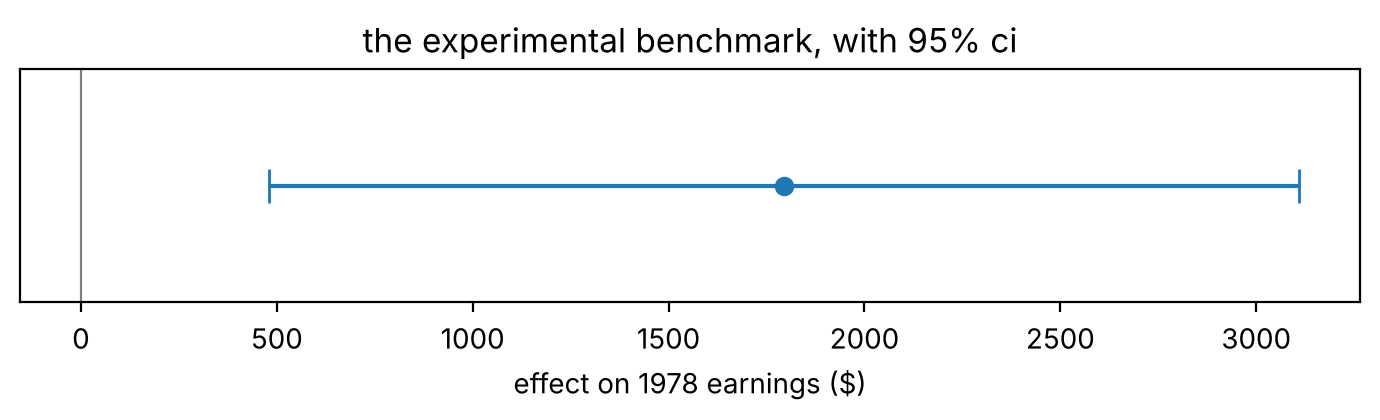

benchmark ATT = $1,794


In [5]:
fig, ax = plt.subplots(figsize=(7, 2.2))
ax.errorbar([diffInMeans], [0], xerr=[[diffInMeans - ciLow], [ciHigh - diffInMeans]], fmt="o", capsize=6)
ax.axvline(0, color="grey", lw=0.8)
ax.set_yticks([])
ax.set_xlabel("effect on 1978 earnings ($)")
ax.set_title("the experimental benchmark, with 95% ci")
plt.tight_layout()
plt.show()

benchmark = diffInMeans  # every later estimate gets graded against this
print(f"benchmark ATT = ${benchmark:,.0f}")

## The benchmark: about **$1,794**

The program raised 1978 earnings by roughly $1,800 for the people who went through it. The 95% interval runs from about $480 to $3,100. That's wide, because 445 people isn't many. **Every estimate in notebooks 2 to 4 gets compared with this number.**

---

### Check your understanding

1. Why can't we just compute $\tau_i$ for each person and average them?
2. A VP asks, "If we make mentoring mandatory for everyone, what happens to attrition?" Is that an ATE or an ATT question?
3. In an experiment, why add covariates at all if they don't fix bias?

<details><summary>Answers</summary>

1. We never see both $Y_i(1)$ and $Y_i(0)$ for the same person. One of them is always missing.
2. Closer to the ATE: it's about everyone, including people who wouldn't have opted in. If the opt-in group benefits more than others would, the ATT will overstate what happens when you mandate it.
3. They soak up outcome variance, which shrinks the standard error. They can also correct small chance imbalances.
</details>

### Interview line
> "When I evaluate a program, I first ask what the experiment would have been. That tells me the estimand, ATT or ATE, and what an ideal comparison group looks like. Then I judge every observational method by how close it gets to that ideal."